#Practical No. 1: Mini Generative AI – Next Word Prediction

In [2]:
import random

# Training sentences
sentences = [
    "I love data science",
    "I love machine learning",
    "data science is amazing",
    "machine learning is powerful",
    "I enjoy learning python"
]

# Dictionary to store word relationships
model = {}

# Build the model
for sentence in sentences:
    words = sentence.split()
    for i in range(len(words) - 1):
        current_word = words[i]
        next_word = words[i + 1]
        if current_word not in model:
            model[current_word] = []
        model[current_word].append(next_word)

print("Learned Model")
print(model)

# User input
word = input("\nEnter starting word: ")
generated_text = word

# Generate text
for i in range(5):
    if word in model:
        word = random.choice(model[word])
        generated_text = generated_text + " " + word
    else:
        break

print("\nGenerated Text:")
print(generated_text)

Learned Model
{'I': ['love', 'love', 'enjoy'], 'love': ['data', 'machine'], 'data': ['science', 'science'], 'machine': ['learning', 'learning'], 'science': ['is'], 'is': ['amazing', 'powerful'], 'learning': ['is', 'python'], 'enjoy': ['learning']}

Enter starting word: Data

Generated Text:
Data


#Practical No. 2: Text Generation and Text Summarization using Generative AI
Part A: Text Generation

In [5]:
responses = {
    "ai": "Artificial Intelligence is transforming the world.",
    "python": "Python is a popular programming language for AI.",
    "data": "Data is the foundation of machine learning."
}

word = input("Enter a keyword (ai/python/data): ").lower()

if word in responses:
    print("\nGenerated Text:")
    print(responses[word])
else:
    print("No text available for the given keyword.")

Enter a keyword (ai/python/data): Data

Generated Text:
Data is the foundation of machine learning.


Part B: Text Summarization using Hugging Face Transformer

In [7]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Load the tokenizer and model directly for summarization
tokenizer = AutoTokenizer.from_pretrained("facebook/bart-large-cnn")
model = AutoModelForSeq2SeqLM.from_pretrained("facebook/bart-large-cnn")

# Input paragraph
text = """
Artificial Intelligence is transforming every industry by automating tasks,
improving decision-making, and generating human-like content.
Generative AI is a branch of AI capable of creating text, images,
music, videos, and even software code.
"""

# Prepare the input for the model
inputs = tokenizer([text], max_length=1024, return_tensors="pt", truncation=True)

# Generate summary
# BART models often use 'generate' with specific parameters for summarization
summary_ids = model.generate(
    inputs["input_ids"],
    num_beams=4,
    min_length=15,
    max_length=40,
    early_stopping=True
)
summary_text = tokenizer.decode(summary_ids[0], skip_special_tokens=True, clean_up_tokenization_spaces=False)

# Display original text
print("Original Text:\n")
print(text)
# Display summary
print("\nGenerated Summary:\n")
print(summary_text)

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

Original Text:


Artificial Intelligence is transforming every industry by automating tasks,
improving decision-making, and generating human-like content.
Generative AI is a branch of AI capable of creating text, images,
music, videos, and even software code.


Generated Summary:

Generative AI is a branch of AI capable of creating text, images,music, videos, and even software code.


# Practical No. 3: AI Tutor Chatbot using Google Gemini API

In [9]:
import os
from google import genai

# Initialize Gemini client
client = genai.Client(api_key="AQ.Ab8RN6JhK6KMsYXkFpwDvCArZB6VmjDMHce0aCIGBUAOB5gihg")

# Create AI Tutor Chat using the officially supported gemini-2.5-flash model
chat = client.chats.create(
    model="gemini-2.5-flash",
    config=genai.types.GenerateContentConfig(
        system_instruction="You are a brilliant AI tutor explaining coding to beginners. Be encouraging and use emojis."
    )
)

print("AI Tutor: Hello! I'm your GenAI tutor. Ask me anything!")

while True:
    user_input = input("You: ")
    if user_input.lower() == "exit":
        print("AI Tutor: Thank you! Happy Learning")
        break
    response = chat.send_message(user_input)
    print("AI Tutor:", response.text)
    print()

AI Tutor: Hello! I'm your GenAI tutor. Ask me anything!
You: Data
AI Tutor: Aha! "Data" – that's a *fantastic* place to start! 🎉 It's like the very first building block of everything we do in coding.

So, what exactly *is* data?

**At its simplest, data is just information.** 🧠

Think about it this way:

*   **Your name** is data ("Alex", "Maria", "Chris").
*   **Your age** is data (25, 30, 42).
*   **Your favorite color** is data ("blue", "green", "purple").
*   **A photo of a cat** is data. 🐱
*   **This very sentence you're reading** is data.

In the world of computers and coding, we deal with data *all the time*. Programs are essentially instructions for computers to process, store, and manipulate data.

**Why is data so important for coders?**

1.  **It's what your program works with:** If you're building a shopping app, the prices of items, the names of products, and user addresses are all data.
2.  **It's how programs make decisions:** "If the user's age data is less than 18, sho

KeyboardInterrupt: Interrupted by user

# Practical No. 4: Introduction to Generative AI using Gemini API
Sub-Part 1: Basic Text Generation

In [12]:
!pip -q install google-generativeai
import google.generativeai as genai
API_KEY = "AQ.Ab8RN6JhK6KMsYXkFpwDvCArZB6VmjDMHce0aCIGBUAOB5gihg"
genai.configure(api_key=API_KEY)
model = genai. GenerativeModel("gemini-2.5-flash")
response = model.generate_content("Explain Artificial Intelligence in simple words.")
print(response.text)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.1/155.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.5/320.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.6/300.6 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 1.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-spanner 3.71.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-datastore 2.26.1 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorboard 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.41.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.

/tmp/ipykernel_2556/389107338.py:2: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


Imagine teaching a computer to **think** or **learn** a bit like a human.

That's basically **Artificial Intelligence (AI)**.

Instead of just following rigid instructions, AI is about programming machines to:

*   **Understand things:** Like when your phone understands your voice command ("Hey Siri, what's the weather?").
*   **Learn from experience:** Like Netflix suggesting movies you might like based on what you've watched before. The more you watch, the better it gets.
*   **Solve problems:** Like a self-driving car figuring out how to navigate traffic safely.
*   **Make decisions:** Like a spam filter deciding if an email is junk or important.

In simple words, **AI is making computers smart enough to perform tasks that typically require human intelligence.** It helps machines see, hear, understand, and even create, getting better over time as they process more information.


Sub-Part 2: AI-Based Story Generation

In [14]:
topic = input("Enter topic: ")
prompt = f"Write a short story on {topic}"
response = model.generate_content(prompt)
print(response.text)

Enter topic: Rabbit
Pip was a rabbit the colour of warm earth, with ears that perpetually twitched and a nose that seemed to be sniffing secrets even in his sleep. He lived in a snug, earthy burrow at the edge of Willow Wood, nestled safely with his mother and four noisy siblings.

Most days, Pip was content to nibble sweet clover near the burrow entrance, keeping an ear cocked for the rustle of a passing badger or the distant shriek of a hawk. But today, a strange feeling hummed in his chest – a whisper of curiosity.

Beyond the familiar patch of short grass, where the sunlight dappled through the leaves of an ancient oak, lay the "Far Meadow." His mother warned them about the Far Meadow; it was too open, too risky. Yet, from their burrow mouth, Pip could see it – a vast expanse of vibrant green, dotted with wildflowers he’d never tasted.

He watched a bumblebee drift lazily towards a particularly plump, purple thistle in the Far Meadow. *What if there were even sweeter thistles there

Sub-Part 3: Question Answering using Generative AI




In [16]:
question = input("Ask anything: ")
response = model.generate_content(question)
print(response.text)

Ask anything: How are u
As an AI, I don't have feelings or a physical state, so I can't really be "good" or "bad" in the human sense.

However, I am functioning perfectly and ready to assist you! How can I help you today?


Sub-Part 4: Text Translation using Generative AI




In [18]:
text = "Artificial Intelligence is the future."
prompt = f"Translate into Hindi:\n{text}"
response = model.generate_content(prompt)
print(response.text)

Here are a couple of ways to translate "Artificial Intelligence is the future" into Hindi, with slight nuances:

1.  **कृत्रिम बुद्धि ही भविष्य है।**
    *   (Kritrim Buddhi hi bhavishya hai.)
    *   This is a very common and natural translation. "ही" (hi) adds emphasis, implying "AI *itself* is the future" or "AI is *indeed* the future."

2.  **आर्टिफिशियल इंटेलिजेंस ही भविष्य है।**
    *   (Artificial Intelligence hi bhavishya hai.)
    *   This option uses the transliterated English term, which is also widely understood and often used in casual and even semi-formal contexts in India.

Both are good, but **कृत्रिम बुद्धि ही भविष्य है।** is generally preferred for its use of Hindi terminology.


 Sub-Part 5: Professional Content Generation


In [20]:
prompt = """ Write a professional leave application for 2 days. """
response = model.generate_content(prompt)
print(response.text)

Here are a few options for a professional leave application for 2 days, depending on whether you have a specific reason you want to share or prefer to keep it general.

---

### Option 1: General Personal Reasons (Most Common)

This is suitable for most situations where you don't need to disclose a specific personal matter.

**Subject: Leave Application - [Your Name] - [Start Date] & [End Date]**

Dear [Manager's Name],

I am writing to formally request two days of leave for personal reasons on **[Start Date, e.g., Monday, October 23rd, 2023]** and **[End Date, e.g., Tuesday, October 24th, 2023]**.

I will ensure all my urgent tasks are completed before my absence. For ongoing responsibilities, I will [mention how you'll handle it, e.g., "brief [colleague's name] on any critical items," or "prepare a handover document"]. I will also set up an out-of-office reply for my email.

I plan to return to work on **[Return Date, e.g., Wednesday, October 25th, 2023]**.

Thank you for considering

 Sub-Part 6: Multiple-Choice Question Generation

In [22]:
topic = "Machine Learning"
prompt = f""" Generate 10 multiple-choice questions on {topic} with answers. """
response = model.generate_content(prompt)
print(response.text)

Here are 10 multiple-choice questions on Machine Learning, covering a range of fundamental concepts:

---

**1. Which type of Machine Learning algorithm learns from data that has been labeled with the correct output?**
    a) Unsupervised Learning
    b) Reinforcement Learning
    c) Supervised Learning
    d) Semi-supervised Learning

**Answer: c) Supervised Learning**
*Explanation: Supervised learning algorithms are trained on a dataset where each input example is paired with an output label.*

---

**2. What is the primary goal of feature scaling techniques like Standardization (Z-score normalization) or Min-Max Scaling?**
    a) To reduce the number of features in the dataset.
    b) To handle missing values in the data.
    c) To bring features to a similar scale, which can improve the performance and convergence of certain algorithms (e.g., gradient descent-based models, SVMs, K-Means).
    d) To prevent overfitting by adding regularization.

**Answer: c) To bring features to a s

# Practical No. 5: Text Generation and Prompt-Based Response Generation using Generative AI

Sub-Part 1: Local Text Generation using GPT-2

In [26]:
!pip install transformers torch
from transformers import pipeline

def generate_local_text(prompt_text: str):
    print("Loading model... (This may take a moment on the first run)")
    # Initialize a text-generation pipeline using standard open-source gpt2
    generator = pipeline('text-generation', model='gpt2')
    print("Generating response...")
    # Generate text based on the prompt
    outputs = generator(
        prompt_text,
        max_length=60,
        num_return_sequences=1,
        pad_token_id=50256 # Prevents warning output
    )
    return outputs[0]['generated_text']

if __name__ == "__main__":
    # Give the model a starting sentence to complete
    sample_prompt = "Artificial Intelligence will change the future of programming by"
    result = generate_local_text(sample_prompt)
    print("\n--- Result ---")
    print(result)

Loading model... (This may take a moment on the first run)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'pad_token_id', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating response...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



--- Result ---
Artificial Intelligence will change the future of programming by making it easy for people to program their own software.

That's why it's important to remember that AI is an artificial intelligence, not some sort of computer. It can't be programmed by human beings, and that's why AI is so important to understand.

What's different about AI today, and what's different about Artificial Intelligence in the future, is that we're moving into a world where there are no human beings. A computer is a machine, and it's designed to carry out its functions.

But there are other ways computers can be used to carry out their functions, such as the way information is stored and used. And that's why we can't just replace human labor with artificial labor in the future. We can't. When the computer comes along and says "I will build a robot that will help me, and you can do that," we can't.

So the only way to keep the machine alive in the future is by keeping it alive, and that's what

Sub-Part 2: Customer Service Response Generation using Gemini


In [28]:
import os
from google import genai
client = genai.Client(api_key="AQ.Ab8RN6JhK6KMsYXkFpwDvCArZB6VmjDMHce0aCIGBUAOB5gihg")

# 1. Provide your custom rules
refund_policy = "Policy: We only allow refunds if the item is broken and reported within 7 days."

# 2. Simulate an incoming customer message
customer_email = "Hi, I bought a shirt 2 days ago but the zipper is completely broken. Can I get my money back?"

# 3. Combine rules and the message into a prompt with closing triple-quotes
prompt = f"""
Use our company policy to answer the customer email politely.
{refund_policy}
Customer Email: {customer_email}
"""

# 4. Generate the reply
response = client.models.generate_content(
    model='gemini-2.5-flash',
    contents=prompt
)

print("Drafted Email Reply:")
print(response.text)

Drafted Email Reply:
Subject: Re: Question About My Recent Shirt Purchase - Broken Zipper

Hi [Customer Name, if you have it, otherwise "Customer"],

Thank you for reaching out to us regarding your recent purchase.

I'm sorry to hear that the zipper on your shirt, purchased two days ago, is completely broken.

According to our company policy, we are happy to process refunds for items that are broken and reported within 7 days of purchase. Since your shirt's zipper is broken and you reported it within the 7-day window, your purchase is eligible for a refund.

To proceed with your refund, please return the shirt to us at your earliest convenience. You can either bring it back to [mention store location if applicable, e.g., "our store at 123 Main Street"] or follow the return instructions on our website [add link if applicable]. Please ensure you have your proof of purchase (receipt or order number) with you.

We apologize for the inconvenience this has caused. Please let us know if you h

# Practical No. 6: Data Analysis and Visualization for AI-Based Insights

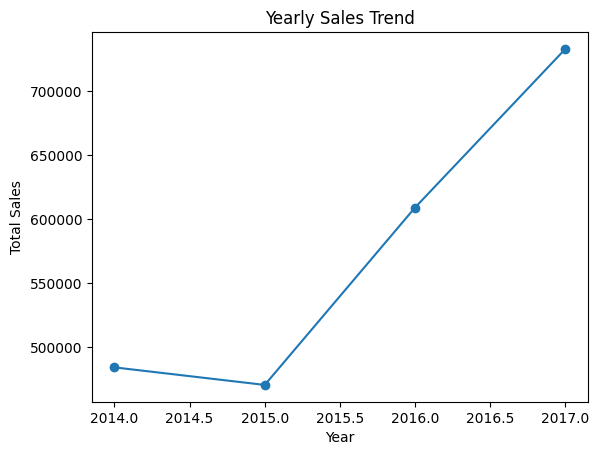

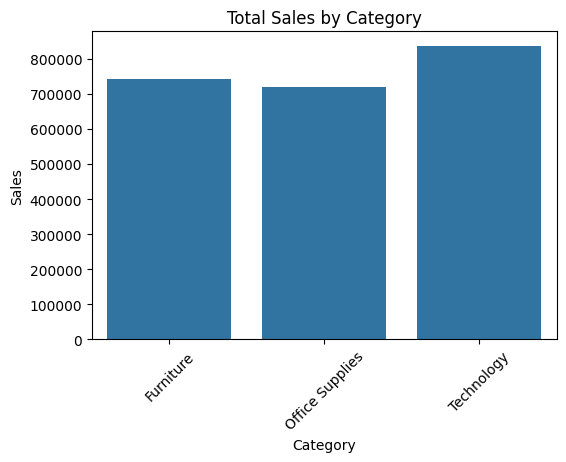

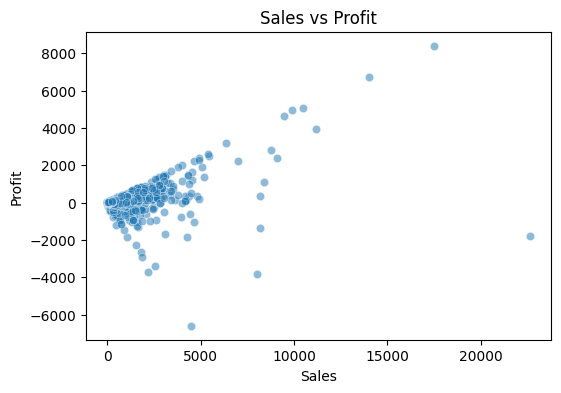

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("/content/Sample - Superstore.csv", encoding='latin1')

# Convert Order Date to datetime
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Sales trend over time
df_grouped = df.groupby(df['Order Date'].dt.year)['Sales'].sum()
df_grouped.plot(kind='line', marker='o', title='Yearly Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.show()

# Sales by Category
plt.figure(figsize=(6, 4))
sns.barplot(x=df['Category'], y=df['Sales'], estimator=sum, errorbar=None)
plt.title('Total Sales by Category')
plt.xticks(rotation=45)
plt.show()

# Profit vs. Sales scatter plot
plt.figure(figsize=(6, 4))
sns.scatterplot(x=df['Sales'], y=df['Profit'], alpha=0.5)
plt.title('Sales vs Profit')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.show()

# Practical No. 7: Dimensionality Reduction using PCA

Original Features: 13
Reduced Features: 2


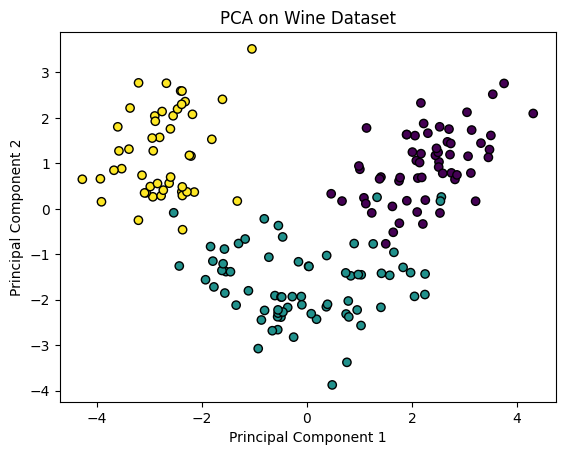

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine
#Load dataset
data = load_wine()
#Create DataFrame
df = pd.DataFrame(
data.data,
columns=data.feature_names
)
# Standardize data
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
# Apply PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(df_scaled)
# Display reduced dimensions
print("Original Features:", df.shape[1])
print("Reduced Features:", pca_data.shape[1])
#Visualize PCA results
plt.scatter(
pca_data[:, 0],
pca_data[:, 1],
c=data.target,
cmap="viridis",
edgecolors="k"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Wine Dataset")
plt.show()

# Practical No. 8: Statistical Analysis and Hypothesis Testing for AI
Part A: One-Way ANOVA

In [36]:
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
# Data: exam scores for each class
A = [85, 90, 88, 82, 87]
B = [76, 78, 80, 81, 75]
C = [92, 88, 94, 89, 90]
# Perform One-Way ANOVA
f_statistic, p_value = stats.f_oneway(A, B, C)
# Display results
print("F-Statistic:", f_statistic)
print("P-Value:", p_value)
#Draw conclusion
alpha = 0.05
if p_value < alpha:
    print("Reject the Null Hypothesis: There is a significant difference in the mean exam scores.")
else:
    print("Fail to Reject the Null Hypothesis: There is no significant difference in the mean exam scores.")

F-Statistic: 28.583333333333343
P-Value: 2.727133500331835e-05
Reject the Null Hypothesis: There is a significant difference in the mean exam scores.


Part B: One-Sample T-Test

In [38]:
import scipy.stats as stats
import numpy as np
#Given student scores
student_scores = [72, 88, 64, 74, 67, 79, 85, 75, 89, 77]
# Hypothesized population mean
hypothesized_mean = 70
# Perform one-sample t-test
t_statistic, p_value = stats.ttest_1samp(
    student_scores,
    hypothesized_mean
)
# Output the results
print(f"T-statistic: {t_statistic}")
print(f"P-value: {p_value}")
# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The sample mean is significantly different from 70.")
else:
    print("Fail to reject the null hypothesis: The sample mean is not significantly different from 70.")

T-statistic: 2.6249999999999996
P-value: 0.027583862030934297
Reject the null hypothesis: The sample mean is significantly different from 70.


Part C: Two-Sample T-Test

In [40]:
import scipy.stats as stats
import numpy as np
#Data for both groups
group1 = [85, 95, 100, 80, 90, 97, 104, 95, 88, 92, 94, 99]
group2 = [83, 85, 96, 92, 100, 104, 94, 95, 88, 90, 93, 94]
#Perform Two-Sample T-Test
t_stat, p_value = stats.ttest_ind(group1, group2)
# Display the result
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")
# Hypothesis testing conclusion
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference in the mean times.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference in the mean times.")

T-statistic: 0.16119885358127883
P-value: 0.8734079490313532
Fail to reject the null hypothesis: There is no significant difference in the mean times.
